# LLM-SR com curvas sintéticas p-OTFT da Org3

Notebook independente para Org3: prepara a divisão por curva, inspeciona train/test_id/test_ood e controla a execução LLM-SR.

A política completa é registrada no manifesto da organização; curvas com tensões repetidas são identificadas pelo arquivo de origem.

## 1. Ambiente e configuração

Use o ambiente Conda `llmsr`. A busca real requer o servidor local LLM-SR. A célula de configuração define semente, limite de amostras e diretório de logs exclusivos desta organização.

In [1]:
from pathlib import Path
import random
import socket
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

def find_workspace(start):
    for candidate in (start, *start.parents):
        if (candidate / "LLM-SR/main.py").is_file() and (candidate / "OTFT-SR/prepare_synthetic_org3.py").is_file():
            return candidate
    raise FileNotFoundError("Não encontrei o workspace LLM-SR/OTFT-SR.")

WORKSPACE_ROOT = find_workspace(Path.cwd().resolve())
OTFT_SR_ROOT = WORKSPACE_ROOT / "OTFT-SR"
LLM_SR_ROOT = WORKSPACE_ROOT / "LLM-SR"
sys.path.insert(0, str(LLM_SR_ROOT))
sys.path.insert(0, str(OTFT_SR_ROOT))

from prepare_synthetic_org3 import build_splits
from llmsr import config as llmsr_config
from llmsr import evaluator as llmsr_evaluator
from llmsr import pipeline as llmsr_pipeline
from llmsr import sampler as llmsr_sampler

SEED = 7
MAX_SAMPLE_NUMS = 100
RUN_PIPELINE = True
SMOKE_MODE = False
LOCAL_LLM_HOST = "127.0.0.1"
LOCAL_LLM_PORT = 5000

plt.style.use("seaborn-v0_8-whitegrid")
print("Workspace:", WORKSPACE_ROOT)

Workspace: /home/ymws/Documentos/llm-sr


## 2. Preparação e manifesto da partição

O adaptador reconstrói os caminhos do índice para o workspace atual, seleciona curvas inteiras e amostra deterministicamente 150 pontos por curva.

In [2]:
split_paths = build_splits()
manifest = __import__("json").loads(split_paths["manifest"].read_text(encoding="utf-8"))
split_summary = pd.DataFrame([
    {
        "split": split_name,
        "n_curvas": split_data["n_curves"],
        "n_pontos": split_data["n_points"],
        "arquivos": ", ".join(curve["csv_file"] for curve in split_data["curves"]),
    }
    for split_name, split_data in manifest["splits"].items()
])
display(split_summary)
print("Manifesto:", split_paths["manifest"])

,split,n_curvas,n_pontos,arquivos
0,train,7,1050,"transfer-neg4V_synth_000.csv, transfer-neg8V_s..."
1,test_id,9,1350,"transfer-neg6V_synth_001.csv, output-neg12V_sy..."
2,test_ood,4,600,"transfer-neg10V_synth_003.csv, transfer-neg12V..."


Manifesto: /home/ymws/Documentos/llm-sr/OTFT-SR/data/synthetic_org3/curve_split_manifest.json


## 3. Política científica de separação

Curvas inteiras são atribuídas a treino, validação `test_id` e extrapolação `test_ood`. O manifesto registra arquivo, tensão, família e justificativa para cada escolha. A divisão é exclusiva por curva, inclusive para tensões nominais repetidas.

In [3]:
split_frames = {
    split_name: pd.read_csv(csv_path)
    for split_name, csv_path in split_paths.items()
    if split_name in {"train", "test_id", "test_ood"}
}
display(pd.concat({
    split_name: frame[["VGS_abs_V", "VDS_abs_V", "log10_ID_abs_A"]].agg(["count", "min", "max"]).T
    for split_name, frame in split_frames.items()
}, axis=1))

train                       test_id                        \
                 count        min        max   count        min        max   
VGS_abs_V       1050.0   0.014000  29.888000  1350.0   0.014000  29.888000   
VDS_abs_V       1050.0   0.000588  19.924000  1350.0   0.000588  19.924000   
log10_ID_abs_A  1050.0 -14.000000  -3.028959  1350.0 -14.000000  -3.029102   

               test_ood                     
                  count     min        max  
VGS_abs_V         600.0   0.014  30.000000  
VDS_abs_V         600.0   0.019  19.924000  
log10_ID_abs_A    600.0 -14.000  -2.872258

## 4. Inspeção da cobertura bivariada

As amostras usam módulos de tensão e corrente. A cor indica log10(|ID|/A), exibido em escala separada por conjunto.

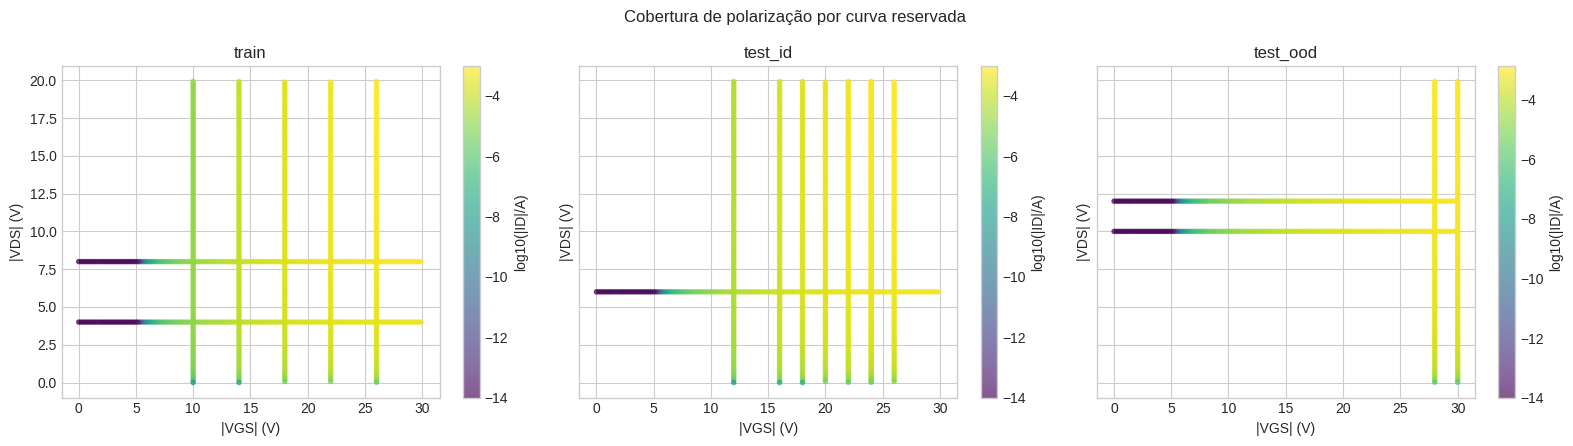

In [4]:
%matplotlib inline
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharex=True, sharey=True)
for ax, (split_name, frame) in zip(axes, split_frames.items()):
    points = ax.scatter(
        frame["VGS_abs_V"], frame["VDS_abs_V"],
        c=frame["log10_ID_abs_A"], s=9, alpha=.65, cmap="viridis"
    )
    ax.set(title=split_name, xlabel="|VGS| (V)", ylabel="|VDS| (V)")
    fig.colorbar(points, ax=ax, label="log10(|ID|/A)")
plt.suptitle("Cobertura de polarização por curva reservada")
plt.tight_layout()
plt.show()

## 5. Especificação e objeto de dados

Somente o conjunto train é entregue ao otimizador. test_id e test_ood permanecem reservados para avaliação fora da busca.

In [5]:
train_frame = split_frames["train"]
input_columns = ["VGS_abs_V", "VDS_abs_V"]
X_train = train_frame[input_columns].to_numpy(dtype=np.float64)
y_train = train_frame["log10_ID_abs_A"].to_numpy(dtype=np.float64)
pipeline_dataset = {"data": {"inputs": X_train, "outputs": y_train}}
specification_path = OTFT_SR_ROOT / "specifications/otft_synthetic_org3_numpy.txt"
specification = specification_path.read_text(encoding="utf-8")
RUN_DIRECTORY = OTFT_SR_ROOT / "logs/org3_synthetic_notebook"
print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("Especificação:", specification_path)

X_train: (1050, 2) | y_train: (1050,)
Especificação: /home/ymws/Documentos/llm-sr/OTFT-SR/specifications/otft_synthetic_org3_numpy.txt


## 6. Execução opcional do pipeline

RUN_PIPELINE=True inicia a busca configurada. Para execução real, o servidor de completions local precisa estar ativo. SMOKE_MODE=True substitui apenas o gerador de candidatas por uma hipótese determinística para verificar o encadeamento sem servidor.

In [6]:
if RUN_PIPELINE and not SMOKE_MODE:
    try:
        with socket.create_connection((LOCAL_LLM_HOST, LOCAL_LLM_PORT), timeout=2):
            print("Servidor local LLM disponível.")
    except OSError as error:
        raise RuntimeError("Inicie o servidor LLM-SR antes de executar a busca.") from error

if RUN_PIPELINE:
    random.seed(SEED)
    np.random.seed(SEED)
    llmsr_sampler.Sampler._global_samples_nums = 1

    if SMOKE_MODE:
        class DeterministicSmokeLLM(llmsr_sampler.LLM):
            def draw_samples(self, prompt, config=None):
                del prompt, config
                return [
                    "    return parameters[0] + parameters[1] * gate_voltage_abs + "
                    "parameters[2] * drain_voltage_abs + "
                    "parameters[3] * gate_voltage_abs * drain_voltage_abs"
                ]
        llm_class = DeterministicSmokeLLM
    else:
        llm_class = llmsr_sampler.LocalLLM

    class_config = llmsr_config.ClassConfig(
        llm_class=llm_class,
        sandbox_class=llmsr_evaluator.LocalSandbox,
    )
    experiment_config = llmsr_config.Config(
        problem_name="org3_otft_synthetic",
        samples_per_prompt=1 if SMOKE_MODE else 4,
    )
    RUN_DIRECTORY.mkdir(parents=True, exist_ok=True)
    llmsr_pipeline.main(
        specification=specification,
        inputs=pipeline_dataset,
        config=experiment_config,
        max_sample_nums=MAX_SAMPLE_NUMS,
        class_config=class_config,
        log_dir=str(RUN_DIRECTORY),
    )
else:
    print("Busca desativada; conjunto de treino foi preparado e inspecionado.")

Servidor local LLM disponível.


INFO:absl:Best score of island 0 increased to -2.639664841052989
INFO:absl:Best score of island 1 increased to -2.639664841052989
INFO:absl:Best score of island 2 increased to -2.639664841052989
INFO:absl:Best score of island 3 increased to -2.639664841052989
INFO:absl:Best score of island 4 increased to -2.639664841052989
INFO:absl:Best score of island 5 increased to -2.639664841052989
INFO:absl:Best score of island 6 increased to -2.639664841052989
INFO:absl:Best score of island 7 increased to -2.639664841052989
INFO:absl:Best score of island 8 increased to -2.639664841052989
INFO:absl:Best score of island 9 increased to -2.639664841052989


================= Evaluated Function =================
def equation(gate_voltage_abs: np.ndarray, drain_voltage_abs: np.ndarray, parameters: np.ndarray) -> np.ndarray:
    """Modelo empírico bivariado para log10(|ID|/A)."""
    return parameters[0] + parameters[1] * gate_voltage_abs + parameters[2] * drain_voltage_abs
------------------------------------------------------
Score        : -2.639664841052989
Sample time  : None
Evaluate time: 0.11790156364440918
Sample orders: None




INFO:absl:Best score of island 4 increased to -0.8366000144717279


================= Evaluated Function =================
def equation(gate_voltage_abs: np.ndarray, drain_voltage_abs: np.ndarray, parameters: np.ndarray) -> np.ndarray:
    """Modelo empírico bivariado para log10(|ID|/A)."""
    """Improved version of `equation_v0` with quadratic term for better fitting capabilities."""
    return parameters[0] + parameters[1] * gate_voltage_abs + parameters[2] * drain_voltage_abs + parameters[3] * (gate_voltage_abs ** 2) + parameters[4] * (drain_voltage_abs ** 2)
------------------------------------------------------
Score        : -0.8366000144717279
Sample time  : 3.723852515220642
Evaluate time: 0.04421854019165039
Sample orders: 2


Execution Error: too many values to unpack (expected 6)
================= Evaluated Function =================
def equation(gate_voltage_abs: np.ndarray, drain_voltage_abs: np.ndarray, parameters: np.ndarray) -> np.ndarray:
    """Modelo empírico bivariado para log10(|ID|/A)."""
    """Improved quadratic model for log10

INFO:absl:Best score of island 7 increased to -2.639620373422558


... (51 outputs left out)

INFO:absl:Best score of island 1 increased to -0.4483213563870474


================= Evaluated Function =================
def equation(gate_voltage_abs: np.ndarray, drain_voltage_abs: np.ndarray, parameters: np.ndarray) -> np.ndarray:
    """Modelo empírico bivariado para log10(|ID|/A)."""
    return parameters[0] + parameters[1] * gate_voltage_abs + parameters[2] * drain_voltage_abs + parameters[3] * (gate_voltage_abs ** 2) + parameters[4] * (drain_voltage_abs ** 2) + parameters[5] * (gate_voltage_abs ** 3) + parameters[6] * (drain_voltage_abs ** 3) + parameters[7] * (gate_voltage_abs ** 2) * (drain_voltage_abs) + parameters[8] * (gate_voltage_abs) * (drain_voltage_abs ** 2) + parameters[9] * (gate_voltage_abs ** 3) * (drain_voltage_abs) + parameters[10] * (gate_voltage_abs) * (drain_voltage_abs ** 3) + parameters[11] * (gate_voltage_abs ** 2) * (drain_voltage_abs ** 2)
------------------------------------------------------
Score        : -0.4483213563870474
Sample time  : 4.035181999206543
Evaluate time: 0.10533428192138672
Sample orders: 88


=====

INFO:absl:Best score of island 6 increased to -0.46069167799790034


================= Evaluated Function =================
def equation(gate_voltage_abs: np.ndarray, drain_voltage_abs: np.ndarray, parameters: np.ndarray) -> np.ndarray:
    """Modelo empírico bivariado para log10(|ID|/A)."""
    a = parameters[0]  # intercept for VGS = 0V
    b = parameters[1]  # slope for VGS
    c = parameters[2]  # curvature for VGS
    d = parameters[3]  # intercept for VDS = 0V
    e = parameters[4]  # slope for VDS
    f = parameters[5]  # curvature for VDS
    g = parameters[6]  # quadratic term for VGS
    h = parameters[7]  # quadratic term for VDS
    
    return a + b * gate_voltage_abs + c * (gate_voltage_abs ** 2) + g * (gate_voltage_abs ** 3) + \
           d + e * drain_voltage_abs + f * (drain_voltage_abs ** 2) + h * (drain_voltage_abs ** 3)
------------------------------------------------------
Score        : -0.46069167799790034
Sample time  : 4.202703535556793
Evaluate time: 0.07204484939575195
Sample orders: 99


================= Evaluated Function 

## 7. Artefatos e avaliação

A divisão exata está em curve_split_manifest.json; os CSVs gerados são reutilizados pelo runner modular. Scores da busca medem MSE somente em treino. Para avaliar generalização, aplique a expressão selecionada a test_id e test_ood sem reajustar parâmetros.

In [8]:
print("Arquivos da partição:")
for split_name in ["train", "test_id", "test_ood", "manifest"]:
    print(split_name, "->", split_paths[split_name])

Arquivos da partição:
train -> /home/ymws/Documentos/llm-sr/OTFT-SR/data/synthetic_org3/train.csv
test_id -> /home/ymws/Documentos/llm-sr/OTFT-SR/data/synthetic_org3/test_id.csv
test_ood -> /home/ymws/Documentos/llm-sr/OTFT-SR/data/synthetic_org3/test_ood.csv
manifest -> /home/ymws/Documentos/llm-sr/OTFT-SR/data/synthetic_org3/curve_split_manifest.json
